In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append('..')

import json
import numpy as np

import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable

from tqdm import tqdm

mpl.rc('text', usetex=True)
mpl.rcParams['text.latex.preamble'] = r"\usepackage{amsmath} \usepackage{xfrac}"

tex_fonts = {"font.family": "serif",
             "font.size": 11,
             "axes.labelsize": 11,
             "legend.fontsize": 11,
             "xtick.labelsize": 8,
             "ytick.labelsize": 8}

plt.rcParams.update(tex_fonts)

marker_options = {'marker': 'o',
                  'markeredgecolor': 'black',
                  'markeredgewidth': 1.0,
                  'markersize': 5}

cmap = sns.color_palette('deep', as_cmap=True)

def set_size(width="revtex4.2", fraction=1, subplots=(1, 1), golden_ratio = 0.6180339887498949):
    """Set figure dimensions to avoid scaling in LaTeX.

    Parameters
    ----------
    width: float or string
            Document width in points, or string of predined document type
    fraction: float, optional
            Fraction of the width which you wish the figure to occupy
    subplots: array-like, optional
            The number of rows and columns of subplots.
    Returns
    -------
    fig_dim: tuple
            Dimensions of figure in inches
    """
    if width == 'revtex4.2':
        width_pt = 510.0
    else:
        width_pt = width

    # Width of figure (in pts)
    fig_width_pt = width_pt * fraction
    # Convert from pt to inches
    inches_per_pt = 1 / 72.27

    # Figure width in inches
    fig_width_in = fig_width_pt * inches_per_pt
    # Figure height in inches
    fig_height_in = fig_width_in * golden_ratio * (subplots[0] / subplots[1])

    return (fig_width_in, fig_height_in)

def load_training_results(file_name: str, data_folder = "../data/optimisation_data/"):
    """
    Save results of the function 'optimize_tn' in json format. 
    Complex values are transformed into strings for json serialisation.
    """
    with open(data_folder + file_name, 'r') as file:
        res = json.load(file)

        # Params during training
        res['params'] = [{int(k): np.array(v, dtype=complex) for k, v in p.items()} for p in res['params']]

        # Params of the MPOs, self-explanatory
        mpo_params_keys = [] #['params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo']
        for key in mpo_params_keys:
            res[key] = {int(k): np.real_if_close(np.array(v, dtype=complex)) for k, v in res[key].items()}
        
        ignore_keys = ['probs', 'data_file', 'params', 'noise_type', 'lr', 'params_true_mpo', 'params_inv_opt_mpo', 'params_inv_true_mpo'] + mpo_params_keys
        for k in set(res.keys()).difference(ignore_keys):
            res[k] = np.real_if_close(np.array(res[k], dtype=complex))
        
    return res

In [2]:
coherent_depol = {'4' : ['cxeven_nq4_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json',
                         'cxeven_nq4_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed112.json',
                         'cxeven_nq4_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed113.json'],
                  '6' : ['cxeven_nq6_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed121.json',
                         'cxeven_nq6_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed122.json',
                         'cxeven_nq6_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed123.json'],
                  '8' : ['cxeven_nq8_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed131.json',
                         'cxeven_nq8_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed132.json',
                         'cxeven_nq8_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed133.json'],
                  '10': ['cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed13.json',
                         'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed14.json',
                         'cxeven_nq10_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-22_seed15.json'],
                  '12': ['cxeven_nq12_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed151.json',
                         'cxeven_nq12_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed152.json',
                         'cxeven_nq12_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed153.json'],
                  '14': ['cxeven_nq14_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1111.json',
                         'cxeven_nq14_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1112.json',
                         'cxeven_nq14_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1113.json'],
                  '16': ['cxeven_nq16_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1114.json',
                         'cxeven_nq16_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1115.json',
                         'cxeven_nq16_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed1116.json'],
                  '18': ['cxeven_nq18_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1120.json',
                         'cxeven_nq18_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1121.json',
                         'cxeven_nq18_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1122.json'],
                  '20': ['cxeven_nq20_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed2010.json',
                         'cxeven_nq20_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed2011.json',
                         'cxeven_nq20_coherent1e-3_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed2012.json']                                                                        
                  }

depol =    {'4' : ['cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json',
                   'cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json',
                   'cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json'],
            '6' : ['cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json',
                   'cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json',
                   'cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json'],
            '8' : ['cxeven_nq8_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json',
                   'cxeven_nq8_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json',
                   'cxeven_nq8_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json'],
            '10': ['cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed13.json',
                   'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed14.json',
                   'cxeven_nq10_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-09_seed15.json'],
            '12': ['cxeven_nq12_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1201.json',
                   'cxeven_nq12_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1202.json',
                   'cxeven_nq12_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed281201.json'],
            '14': ['cxeven_nq14_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1401.json',
                   'cxeven_nq14_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1402.json',
                   'cxeven_nq14_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1403.json'],  
            '16': ['cxeven_nq16_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1601.json',
                   'cxeven_nq16_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1602.json',
                   'cxeven_nq16_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1603.json'],  
            '18': ['cxeven_nq18_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1801.json',
                   'cxeven_nq18_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1802.json',
                   'cxeven_nq18_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed1803.json'],  
            '20': ['cxeven_nq20_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed2002.json',
                   'cxeven_nq20_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed2002.json',
                   'cxeven_nq20_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-24_seed281201.json'],                                      
            }

spl_nazca =      {'4': ['cxeven_nq4_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28401.json',
                  'cxeven_nq4_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28402.json',
                  'cxeven_nq4_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28403.json'], 
            '6': ['cxeven_nq6_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28601.json',
                  'cxeven_nq6_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28602.json',
                  'cxeven_nq6_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28603.json'], 
            '8': ['cxeven_nq8_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28801.json',
                  'cxeven_nq8_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28802.json',
                  'cxeven_nq8_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-28_seed28803.json'],    
            '10': ['cxeven_nq10_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91001.json',
                   'cxeven_nq10_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91002.json',
                   'cxeven_nq10_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91003.json'],
            '12': ['cxeven_nq12_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91201.json',
                   'cxeven_nq12_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91202.json',
                   'cxeven_nq12_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed91203.json'],  
            '14': ['cxeven_nq14_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281404.json',
                   'cxeven_nq14_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281402.json',
                   'cxeven_nq14_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281403.json'],  
            '16': ['cxeven_nq16_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281604.json',
                   'cxeven_nq16_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281602.json',
                   'cxeven_nq16_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281603.json'],  
            '18': ['cxeven_nq18_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281801.json',
                   'cxeven_nq18_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281802.json',
                   'cxeven_nq18_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed281803.json'],    
            '20': ['cxeven_nq20_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed282001.json',
                   'cxeven_nq20_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed282002.json',
                   'cxeven_nq20_ext_gen_dict_bigger_231106_nazca_50q_ns1000000_global_repeated_sic_states_2023-11-24_seed282003.json'],                                        
           }

spl_kyiv = {'4': ['cxeven_nq4_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed10.json',
                  'cxeven_nq4_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed11.json',
                  'cxeven_nq4_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed12.json'],
            '6': ['cxeven_nq6_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed20.json',
                  'cxeven_nq6_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed21.json',
                  'cxeven_nq6_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed22.json'],
            '8': ['cxeven_nq8_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed30.json',
                  'cxeven_nq8_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed31.json',
                  'cxeven_nq8_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed32.json'],
            '10': ['cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed46.json',
                   'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed47.json',
                   'cxeven_nq10_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-29_seed48.json'],
            '12': ['cxeven_nq12_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed50.json',
                   'cxeven_nq12_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed51.json',
                   'cxeven_nq12_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed52.json'],  
            '14': ['cxeven_nq14_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed60.json',
                   'cxeven_nq14_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed9992.json',
                   'cxeven_nq14_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed62.json'],  
            '16': ['cxeven_nq16_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed70.json',
                   'cxeven_nq16_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed71.json',
                   'cxeven_nq16_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed72.json'],  
            '18': ['cxeven_nq18_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed80.json',
                   'cxeven_nq18_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed81.json',
                   'cxeven_nq18_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed82.json'],    
            '20': ['cxeven_nq20_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed90.json',
                   'cxeven_nq20_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed91.json',
                   'cxeven_nq20_gen_dict_bigger_231127_kyiv_50q_ns1000000_global_repeated_sic_states_2023-11-30_seed92.json'],                                        
           }

# Plot with error bars

In [11]:
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace']

noise_models = {'depol': depol, 'coherent_depol': coherent_depol, 'spl': spl_kyiv}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"Importing {noise_type}")         
    
    best_frob_dists = {}
    for qubs, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_vals = np.array([dist[idx] for dist, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        best_frob_dists[qubs] = np.mean(best_vals), np.std(best_vals) # mean value and std
        #best_frob_dists[qubs] = np.min(best_vals), 0 * np.std(best_vals) # min value

    processed_data[noise_type] = best_frob_dists
    print("")

processed_data

Importing depol
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json
 > Loading and processing file: cxeven_nq8_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq8_even_depol

{'depol': {'4': (2.7436460468561894e-05, 1.0906781922329504e-06),
  '6': (5.2823439611734045e-05, 2.326204630980646e-06),
  '8': (3.253454130954422e-05, 1.1277731263502947e-06),
  '10': (4.9291838731998126e-05, 2.8806340542332763e-06),
  '12': (6.459965342386907e-05, 3.6615632191754158e-06),
  '14': (9.068857073638951e-05, 4.614218073061587e-06),
  '16': (0.00011165499250798128, 4.611214132784726e-06),
  '18': (0.00010906497875362575, 2.6693124889362026e-06),
  '20': (0.0001230695068759058, 1.7477316089328614e-06)},
 'coherent_depol': {'4': (1.7393992079270884e-05, 4.245922933179384e-07),
  '6': (3.793387590467213e-05, 6.182710687271059e-07),
  '8': (4.6848254428799585e-05, 1.7753665678602358e-06),
  '10': (6.721373046980617e-05, 8.664027846253835e-07),
  '12': (5.7024127541531e-05, 1.1673127956703791e-06),
  '14': (9.951958412453739e-05, 1.0387835642356664e-06),
  '16': (8.5961281018417e-05, 2.9733927987698756e-06),
  '18': (0.00014256532768064378, 4.1793467364216615e-06),
  '20': (0.

In [21]:
# Linear fit for spl channel
nn = 'spl'
xx = np.array(list(processed_data[nn].keys()), dtype=int)
yy = np.array(list(processed_data[nn].values()))[:, 0]
m, q = np.polyfit(xx, yy, deg=1)
print(m, q)

# Linear fit for depol channels
y1 = np.array(list(processed_data['depol'].values()))[:, 0]
y2 = np.array(list(processed_data['coherent_depol'].values()))[:, 0]
yy = np.hstack([y1, y2])
xx = np.hstack([xx, xx])
m, q = np.polyfit(xx, yy, deg = 1)
print(m, q)

1.4309612281127883e-05 9.836650814658169e-06
6.583237203645051e-06 -4.877612829256633e-06


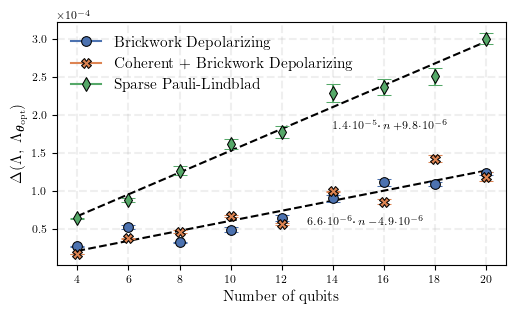

In [22]:
markersize = 7
capsize = 5

markers = ['o', 'X', 'd']
labels = ["Brickwork Depolarizing", "Coherent + Brickwork Depolarizing", "Sparse Pauli-Lindblad"]

fig = plt.figure(figsize=set_size(fraction=0.75))

xx = np.arange(4, 22, 2)
plt.plot(xx, 1.431e-5 * xx + 9.836650814658169e-06, ls = "--", c='k')
plt.text(14, 1.8e-4, r"${\scriptstyle 1.4\cdot 10 ^{-5}\boldsymbol{\cdot}\,n\, + 9.8\cdot10^{-6}}$", fontsize = 11)

plt.text(13, 0.55e-4, r"${\scriptstyle 6.6\cdot10 ^{-6}\boldsymbol{\cdot}\,n\, - 4.9\cdot10^{-6}}$", fontsize = 11)
plt.plot(xx, 6.58323721e-06 * xx -4.87761287e-06, ls = "--", c='k')

# Noise with error-bars
for (noise_key, vals_dicts), color, marker, label in zip(processed_data.items(), cmap, markers, labels):

    for q, v in vals_dicts.items():
        plt.errorbar(int(q), v[0], yerr = v[1], color = color, marker = marker,  markersize = markersize, capsize = capsize, markeredgecolor='black', capthick=10, mew=0.75)
    plt.errorbar([], [], color = color, marker = marker, markersize = markersize, capsize = capsize, markeredgecolor='black', label=label, mew=0.75)

plt.xticks([int(k) for k in vals_dicts.keys()])

plt.xlabel(r"Number of qubits")
plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.legend(frameon=False)

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.tight_layout()
#plt.savefig('delta_accuracy_vs_qubits.pdf', format="pdf")

# Plot without error bars

In [23]:
metrics_keys = ['frob_distance', 'test_loss', 'lpdo_trace']

noise_models = {'depol': depol, 'coherent_depol': coherent_depol, 'spl': spl_kyiv}

processed_data = {}
for noise_type, noise_data in noise_models.items():  
    print(f"Importing {noise_type}")         
    
    best_frob_dists = {}
    for qubs, files in noise_data.items():
        
        tmp_dict = {k: [] for k in metrics_keys}
        for f in files:
            print(f" > Loading and processing file: {f}")
            data = load_training_results(f)
            [tmp_dict[k].append(data[k]) for k in tmp_dict.keys()]

        idx_min_loss = [np.argmin(yy) for yy in tmp_dict['test_loss']]
        best_vals = np.array([dist[idx] for dist, idx in zip(tmp_dict['frob_distance'], idx_min_loss)])
        #best_frob_dists[qubs] = np.mean(best_vals), np.std(best_vals) # mean value and std
        best_frob_dists[qubs] = np.min(best_vals), 0 * np.std(best_vals) # min value

    processed_data[noise_type] = best_frob_dists
    print("")

processed_data

Importing depol
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json
 > Loading and processing file: cxeven_nq4_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed102.json
 > Loading and processing file: cxeven_nq6_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed103.json
 > Loading and processing file: cxeven_nq8_even_depol1e-3_odd_depol5e-4_ns1000000_global_repeated_sic_states_2023-11-23_seed101.json
 > Loading and processing file: cxeven_nq8_even_depol

{'depol': {'4': (2.5955445562047505e-05, 0.0),
  '6': (5.0540163391010744e-05, 0.0),
  '8': (3.1130417311953096e-05, 0.0),
  '10': (4.526245243197114e-05, 0.0),
  '12': (6.0414009348419555e-05, 0.0),
  '14': (8.727703485500447e-05, 0.0),
  '16': (0.00010663223913454088, 0.0),
  '18': (0.00010538686683292386, 0.0),
  '20': (0.00012059784113116478, 0.0)},
 'coherent_depol': {'4': (1.691244482288877e-05, 0.0),
  '6': (3.7274939215681264e-05, 0.0),
  '8': (4.4446498428718506e-05, 0.0),
  '10': (6.600421999825025e-05, 0.0),
  '12': (5.59572540826947e-05, 0.0),
  '14': (9.829732252752966e-05, 0.0),
  '16': (8.179950755971001e-05, 0.0),
  '18': (0.00013878318139159962, 0.0),
  '20': (0.0001104041025868918, 0.0)},
 'spl': {'4': (6.308339349438061e-05, 0.0),
  '6': (8.465161938886467e-05, 0.0),
  '8': (0.00012207344238179818, 0.0),
  '10': (0.00015287812417097424, 0.0),
  '12': (0.00016782449049446146, 0.0),
  '14': (0.00021847564635169014, 0.0),
  '16': (0.00022288416206905917, 0.0),
  '18': (

In [28]:
nn = 'spl'
xx = np.array(list(processed_data[nn].keys()), dtype=int)
yy = np.array(list(processed_data[nn].values()))[:, 0]
m_spl, q_spl = np.polyfit(xx, yy, deg=1)
print(m_spl, q_spl)

y1 = np.array(list(processed_data['depol'].values()))[:, 0]
y2 = np.array(list(processed_data['coherent_depol'].values()))[:, 0]
yy = np.hstack([y1, y2])
xx = np.hstack([xx, xx])
m_dep, q_dep = np.polyfit(xx, yy, deg = 1)
print(m_dep, q_dep)

1.3666353172994257e-05 9.430473999488702e-06
6.34007665435603e-06 -4.798923151550117e-06


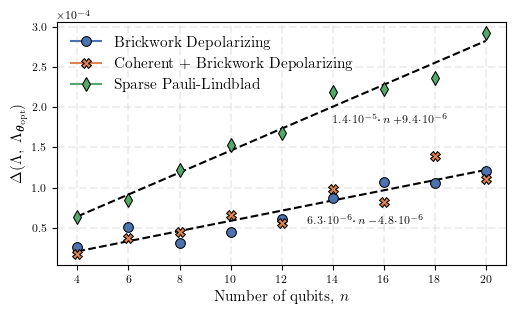

In [31]:
markersize = 7
capsize = 5

markers = ['o', 'X', 'd']
labels = ["Brickwork Depolarizing", "Coherent + Brickwork Depolarizing", "Sparse Pauli-Lindblad"]

fig = plt.figure(figsize=set_size(fraction=0.75))

xx = np.arange(4, 22, 2)
plt.plot(xx, m_spl * xx + q_spl, ls = "--", c='k')
plt.text(14, 1.8e-4, r"${\scriptstyle 1.4\cdot 10 ^{-5}\boldsymbol{\cdot}\,n\, + 9.4\cdot10^{-6}}$", fontsize = 11)

plt.text(13, 0.55e-4, r"${\scriptstyle 6.3\cdot10 ^{-6}\boldsymbol{\cdot}\,n\, - 4.8\cdot10^{-6}}$", fontsize = 11)
plt.plot(xx, m_dep * xx + q_dep, ls = "--", c='k')

# Noise with error-bars
for (noise_key, vals_dicts), color, marker, label in zip(processed_data.items(), cmap, markers, labels):

    for q, v in vals_dicts.items():
        plt.errorbar(int(q), v[0], yerr = v[1], color = color, marker = marker,  markersize = markersize, capsize = 0 * capsize, markeredgecolor='black', capthick=10, mew=0.75)
    plt.errorbar([], [], color = color, marker = marker, markersize = markersize, capsize = capsize, markeredgecolor='black', label=label, mew=0.75)

plt.xticks([int(k) for k in vals_dicts.keys()])

plt.xlabel(r"Number of qubits, $n$")
plt.ylabel(r"$\Delta(\Lambda,~\Lambda_{\boldsymbol{\theta_\textrm{opt}}})$")

plt.legend(frameon=False)

plt.grid(ls = "--", lw = 1.5, alpha = 0.2)

plt.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
plt.tight_layout()
plt.savefig('delta_accuracy_vs_qubits_noerrbars.pdf', format="pdf")